## Part 3: Methods Application — Classification

**Dataset:** `dataset_grupo_22.csv`, with 2000 patient profiles. **Variable to predict:** `target_class`, the
diagnostic category (`DI_HY`, `HT`, `DI_HT`). The clinical meaning of the codes is not given in the assignment.

### Objective
1. Apply **Logistic Regression** and **Linear Discriminant Analysis (LDA)** and **decide which method is most
   appropriate**, with justification.
2. Evaluate using the resampling methods: ***holdout***, **cross-validation (k = 5 and k = 10)**, **LOOCV** and
   ***bootstrap***.
3. Choose appropriate metrics and **explain how the variance is affected by the resampling method**.

### Starting point: what the EDA already told us
| EDA finding | Consequence for classification |
|---|---|
| `target_class` is **highly imbalanced**: 89.9% `DI_HY`, 5.85% `HT`, 4.25% `DI_HT` | An unadjusted model tends to predict `DI_HY` almost always. *Accuracy* is misleading; per-class metrics and **stratified** resampling are needed. |
| `HbA1c_level` strongly separates `HT` from the other classes (η² = 0.41); `triglycerides` separates `DI_HY` from the minority classes (η² = 0.105) | We expect `HT` to be relatively easy to identify and these to be the most important features. |
| `DI_HT` and `DI_HY` overlap heavily | `DI_HT` should be the hardest class. |
| The distributions are far from "normal" (uniform, skewed, long tails) | The LDA assumptions may not hold (checked in 2.1). |
| Decimal-precision artefact linked to the class | Logistic Regression and LDA use the numeric value linearly and do not exploit decimal places; we create no features from them. |

## 1. Data preparation

### 1.1 Loading the data and setting up the environment

We load the original dataset (without modifying it) and fix the random seed at **22** (project rule), so that every
data split, cross-validation and *bootstrap* resample is reproducible.

In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, LeaveOneOut,
                                     cross_val_predict, cross_validate)
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score,
                             precision_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)

SEED = 22
np.random.seed(SEED)
pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')

dataset_name = 'dataset_grupo_22.csv'
dataset_path = next(p for p in [Path.cwd() / dataset_name, Path.cwd().parent / dataset_name] if p.is_file())
raw = pd.read_csv(dataset_path)
print('Dataset shape:', raw.shape)
raw['target_class'].value_counts().to_frame('n').assign(**{'%': lambda d: d['n'] / len(raw) * 100})

Dataset shape: (2000, 35)


,n,%
target_class,,
DI_HY,1798,89.900
HT,117,5.850
DI_HT,85,4.250


**Conclusions:** the dataset has **2000 records**: 1798 `DI_HY` (89.9%), 117 `HT` (5.85%) and **only 85 `DI_HT`
(4.25%)**. The majority class is 21 times larger than the smallest one. This number will shape everything that
follows: the choice of metrics, the need for stratification and the behaviour of the models.

### 1.2 Feature removal, encoding and predictor matrix

We apply **the same preparation as in the regression notebook**, for the same reasons (EDA, `01_EDA`):
- we remove `calcium_baseline` (constant), `systolic_index` (copy of `systolic_bp`) and `age_normalized` (rescaling
  of `age`). The last two would make the covariance matrix **singular**, which is a direct problem for LDA, since it
  has to invert that matrix;
- we also remove `ldl_alternative`: it has the same values as `ldl`, but shuffled across patients (it matches on only
  18 of 2000 rows). The value does not belong to the patient in that row, so it is noise;
- we convert the categorical variables into numbers (ordinal → 0, 1, 2…; binary → 0/1; `employment_status` →
  *one-hot*);
- **we remove both targets from the predictors**: `target_class` is what we want to predict and `target_regression`
  is the other outcome of the assignment.

All remaining 30 features are kept. Feature selection is the topic of Part 4 (Ridge/Lasso); here the goal is to
compare classification and resampling methods under the same conditions.

In [2]:
TARGET = 'target_class'
CLASSES = ['DI_HY', 'HT', 'DI_HT']          # fixed order: majority -> minorities
DROP_EDA = ['calcium_baseline', 'systolic_index', 'age_normalized', 'ldl_alternative']
ORDINAL = {
    'age_level': ['Young', 'Middle', 'Mature', 'Senior'],
    'bmi_level': ['Underweight', 'Normal', 'Overweight', 'Obese'],
    'smoking': ['Never', 'Former', 'Current'],
    'physical_activity': ['Low', 'Moderate', 'High'],
    'stress_level': ['Low', 'Medium', 'High'],
    'sugar_consumption': ['Low', 'Medium', 'High'],
    'education_level': ['Primary', 'Secondary', 'Tertiary'],
}
BINARY = {'gender': 'Male', 'family_history': 'Yes', 'low_hdl_cholesterol': 'Yes', 'high_ldl_cholesterol': 'Yes'}

data = raw.drop(columns=DROP_EDA).copy()
for col, levels in ORDINAL.items():
    data[col] = data[col].map({lvl: i for i, lvl in enumerate(levels)})
for col, positive in BINARY.items():
    data[col] = (data[col] == positive).astype(int)
data = pd.get_dummies(data, columns=['employment_status'], drop_first=True, dtype=int)

X = data.drop(columns=[TARGET, 'target_regression'])
y = data[TARGET]
assert X.isna().sum().sum() == 0
FEATURES = list(X.columns)
print(f'{X.shape[0]} records x {len(FEATURES)} features')

2000 records x 30 features


**Conclusions:** **30 features** remain for the 2000 records, with no missing values. With about 67 records per
feature, there is enough data to estimate a Logistic Regression or an LDA with a common covariance matrix.

Even so, the `DI_HT` class has only 85 patients. This rules out, for example, a **QDA**: it would have to estimate a
30×30 covariance matrix (465 parameters) from those 85 patients alone, and the estimate would be very unstable. This
is one of the reasons we stick to the two methods requested.

### 1.3 Evaluation metrics: why *accuracy* is not enough

The EDA showed that `target_class` is **highly imbalanced** (≈ 90% `DI_HY`). Under these conditions *accuracy* is
misleading: a model that always answers `DI_HY` is right ≈ 90% of the time without having learned anything. We
therefore use the following metrics, adapted to 3 classes:

| Metric | What it measures | Why it is useful here |
|---|---|---|
| **Recall per class** | Of the patients in each class, how many were correctly identified | Shows directly whether the rare classes (`HT`, `DI_HT`) are being detected |
| **Precision per class** | Of the predictions for each class, how many are correct | Shows the cost of "inventing" diagnoses |
| **Macro F1** (main metric) | Simple average of the F1 of the 3 classes | Every class weighs the same, so missing a rare class lowers the metric a lot |
| **Balanced accuracy** | Simple average of the 3 class recalls | A model that always predicts the majority class scores 1/3 = 0.333 |
| *Accuracy* | Proportion of correct predictions | Secondary reference only |
| **Confusion matrix** | Which classes are confused with which | Detailed diagnosis of the errors |

To make this concrete, we evaluate a **reference classifier** (*baseline*) that always predicts the majority class.

In [3]:
def metrics(y_true, y_pred):
    rec = recall_score(y_true, y_pred, labels=CLASSES, average=None, zero_division=0)
    return {'f1_macro': f1_score(y_true, y_pred, labels=CLASSES, average='macro', zero_division=0),
            'bal_acc': balanced_accuracy_score(y_true, y_pred),
            'accuracy': accuracy_score(y_true, y_pred),
            **{f'recall_{c}': r for c, r in zip(CLASSES, rec)}}

baseline_pred = np.full(len(y), 'DI_HY')
pd.Series(metrics(y, baseline_pred), name='baseline (always DI_HY)').to_frame().T

,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT
baseline (always DI_HY),0.316,0.333,0.899,1.000,0.000,0.000


**Conclusions:** the classifier that always answers `DI_HY` has an **accuracy of 0.899**, which looks like a good
result. But it identifies **no** `HT` or `DI_HT` patient (recall = 0), and therefore has:
- **macro F1 = 0.316**;
- **balanced accuracy = 0.333** (= 1/3).

**Justification:** this is numerical proof that *accuracy* cannot be the main metric for this problem. From here on,
the main metric is **macro F1**, complemented by **balanced accuracy** and the **recall of each class**. Any useful
model must be clearly above 0.316 and 0.333.

## 2. Logistic Regression vs LDA

**Logistic Regression:** models the probability of each class directly,
$P(Y=k \mid X) = \frac{e^{\beta_{k0} + \beta_k^T x}}{\sum_j e^{\beta_{j0} + \beta_j^T x}}$ (multinomial
version), with coefficients estimated by **maximum likelihood**. It **assumes nothing** about the distribution of
the features.

**LDA:** models the distribution of the features **within each class** as multivariate normal, with a **common
covariance matrix**, and uses Bayes' theorem, $P(Y=k \mid X) \propto \pi_k \, f_k(x)$, where $\pi_k$ is the
prior probability of the class. The decision boundaries are linear.

**Strategy:**
1. check whether the LDA assumptions hold in our data (2.1);
2. fit both methods without adjustments and look at the effect of the imbalance (2.2);
3. correct the imbalance and compare (2.3);
4. test whether the differences are statistically significant (2.4).

### 2.1 Do the LDA assumptions hold?

LDA assumes that, **within each class**, the features follow a **normal** distribution and that
**all classes share the same covariance matrix**. Logistic Regression makes no such assumptions. Knowing whether the
assumptions hold helps us understand which method should perform better.

For the most discriminative features from the EDA, we check:
- **normality within each class** (Shapiro-Wilk test and skewness);
- **equality of variances across classes** (Levene's test and the ratio between the largest and smallest standard
  deviation).

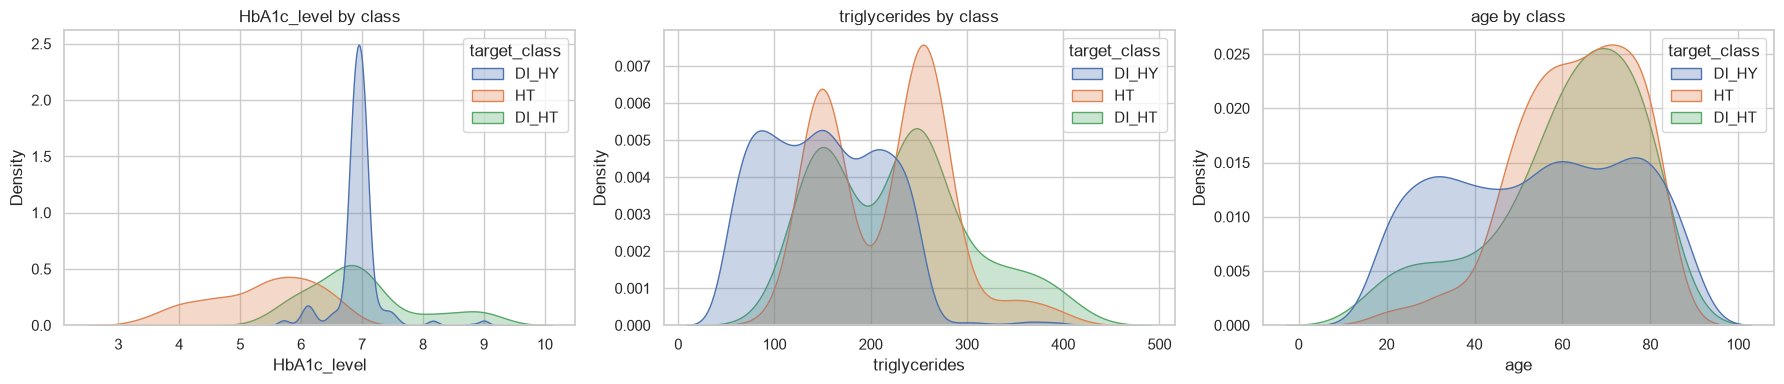

,std_DI_HY,std_HT,std_DI_HT,std_ratio (max/min),p_Levene,skew_DI_HY,p_Shapiro_DI_HY
feature,,,,,,,
HbA1c_level,0.359,0.868,0.907,2.528,0.000,1.368,0.000
triglycerides,61.097,63.418,75.080,1.229,0.072,0.311,0.000
age,20.662,13.346,16.871,1.548,0.000,-0.080,0.000
bmi,7.285,6.013,5.819,1.252,0.000,0.086,0.000
blood_pressure,4.416,8.181,11.553,2.616,0.000,-0.733,0.000
crp_level,0.939,1.530,2.537,2.702,0.000,0.441,0.000


In [4]:
key = ['HbA1c_level', 'triglycerides', 'age', 'bmi', 'blood_pressure', 'crp_level']
rows = []
for f in key:
    groups = [data.loc[y == c, f] for c in CLASSES]
    stds = [g.std() for g in groups]
    rows.append({'feature': f,
                 **{f'std_{c}': s for c, s in zip(CLASSES, stds)},
                 'std_ratio (max/min)': max(stds) / min(stds),
                 'p_Levene': stats.levene(*groups).pvalue,
                 'skew_DI_HY': stats.skew(groups[0]),
                 'p_Shapiro_DI_HY': stats.shapiro(groups[0].sample(500, random_state=SEED)).pvalue})
assumptions = pd.DataFrame(rows).set_index('feature')

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, f in zip(axes, ['HbA1c_level', 'triglycerides', 'age']):
    sns.kdeplot(data=data, x=f, hue=y, hue_order=CLASSES, common_norm=False, fill=True, alpha=.3, ax=ax)
    ax.set_title(f'{f} by class')
plt.tight_layout(); plt.show()
assumptions

**Conclusions:** **the LDA assumptions do not hold.**
- **Normality:** the Shapiro-Wilk test rejects normality (p < 0.001) for every feature tested. The plots show clearly
  non-normal distributions, e.g. `HbA1c_level` very concentrated in `DI_HY` (skewness 1.37) and `age` roughly
  uniform.
- **Equal covariances:** Levene's test rejects equal variances across classes for 5 of the 6 features. For
  `HbA1c_level`, the standard deviation of the minority classes (≈ 0.87–0.91) is **2.5 times** that of `DI_HY` (0.36);
  for `blood_pressure` and `crp_level` the ratio also exceeds 2.6.

**What this implies:** in principle, these violations favour Logistic Regression, which does not depend on these
assumptions. However, LDA is known to be **robust** to moderate violations: its decision boundaries remain linear and
can work well even if the estimated probabilities are not exact. The choice between the two methods must therefore be
made from the **results**, not from theory alone.

The plots also confirm the EDA: `HbA1c_level` separates `HT` well (lower values), `triglycerides` shifts `HT` and
`DI_HT` towards higher values, and the `DI_HT` and `DI_HY` curves overlap heavily.

### 2.2 First fit: Logistic Regression and LDA "out of the box"

We fit both methods with scikit-learn's default options:
- **Multinomial Logistic Regression** (generalisation of the logistic model to 3 classes, using *softmax*),
  estimated by maximum likelihood. Features are standardised (`StandardScaler`) because scikit-learn
  applies a small default regularisation that depends on scale;
- **LDA**, which estimates the class means, a common covariance and the **prior probabilities** πₖ from the class
  proportions in the training data.

To avoid depending on a single data split, we use **stratified 10-fold cross-validation**: every patient receives a
prediction made by a model that never saw them. This is the default resampling method; section 3 compares it with the
others.

**Hypothesis to test:** since ~90% of patients are `DI_HY`, we expect the unadjusted models to predict `DI_HY` in most
cases and to miss the minority classes.

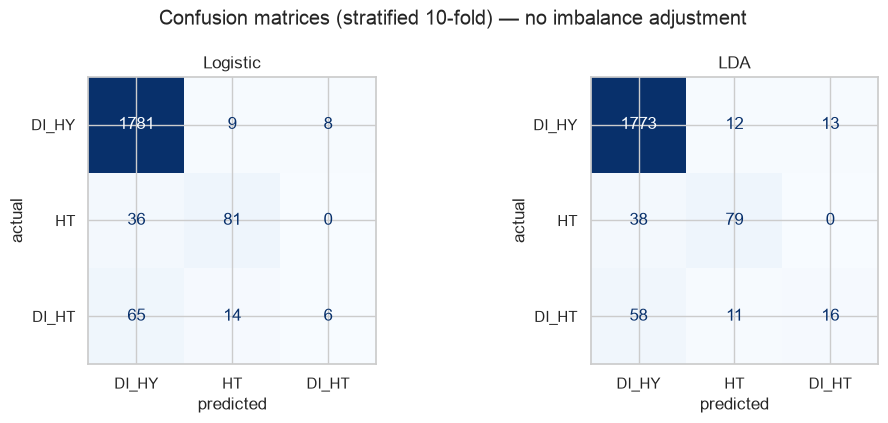

,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT
Logistic,0.607,0.584,0.934,0.991,0.692,0.071
LDA,0.656,0.617,0.934,0.986,0.675,0.188
baseline (always DI_HY),0.316,0.333,0.899,1.000,0.000,0.000


In [5]:
MODELS = {
    'Logistic':          make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    'LDA':                make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
    'Logistic (weighted)':  make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight='balanced')),
    'LDA (equal priors)': make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(priors=[1/3] * 3)),
}
CV10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

def show_confusions(names, preds, title):
    fig, axes = plt.subplots(1, len(names), figsize=(5.2 * len(names), 4.3))
    for ax, n in zip(np.atleast_1d(axes), names):
        ConfusionMatrixDisplay(confusion_matrix(y, preds[n], labels=CLASSES), display_labels=CLASSES).plot(
            ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(n); ax.set_xlabel('predicted'); ax.set_ylabel('actual')
    fig.suptitle(title); plt.tight_layout(); plt.show()

cv_preds = {n: cross_val_predict(m, X, y, cv=CV10) for n, m in MODELS.items()}
show_confusions(['Logistic', 'LDA'], cv_preds, 'Confusion matrices (stratified 10-fold) — no imbalance adjustment')
first = pd.DataFrame({n: metrics(y, cv_preds[n]) for n in ['Logistic', 'LDA']}).T
first.loc['baseline (always DI_HY)'] = metrics(y, baseline_pred)
first

**Conclusions: the hypothesis is confirmed.** Without adjustments, both models predict `DI_HY` almost always.

| | Macro F1 | Bal. acc. | Accuracy | Recall `DI_HY` | Recall `HT` | Recall `DI_HT` |
|---|---|---|---|---|---|---|
| Baseline (always `DI_HY`) | 0.316 | 0.333 | 0.899 | 1.000 | 0.000 | 0.000 |
| Logistic | 0.607 | 0.584 | 0.934 | 0.991 | 0.692 | **0.071** |
| LDA | **0.656** | **0.617** | 0.934 | 0.986 | 0.675 | **0.188** |

- **`DI_HY`** is recognised almost always (recall ≈ 0.99).
- **`HT`** is reasonably well detected (recall ≈ 0.68–0.69 for both models), thanks to `HbA1c_level`, which
  separates this class well.
- **`DI_HT`** is almost never detected. Logistic Regression gets only 6 of the 85 patients right (7%); LDA gets 16
  (19%). In the confusion matrix, most `DI_HT` appear as `DI_HY`.
- *Accuracy* (0.93) looks excellent, but it is measuring mostly the majority class.

**Justification — why does this happen?** Both methods aim to minimise the **total** error. With 1798 `DI_HY` against
85 `DI_HT`, and with `DI_HT` heavily overlapping `DI_HY` (EDA), the "cheapest" way to make few errors is to classify
uncertain cases as `DI_HY`. In LDA this is explicit: the prior probability of `DI_HY` is 0.90 versus 0.04 for `DI_HT`,
and Bayes' rule favours the more frequent class.

**Why does LDA detect more `DI_HT` than Logistic Regression?** LDA uses the covariance structure of all classes at
once (the class means and a common covariance). When a class has few examples, this gives more stable estimates than
Logistic Regression, which fits separate coefficients for each class from the few cases available.

### 2.3 Correcting the imbalance

The problem in 2.2 has a known cause for each method:
- in **Logistic Regression**, the likelihood is a sum over all patients. With 1798 `DI_HY` against 85 `DI_HT`,
  misclassifying a `DI_HT` costs almost nothing in total. With `class_weight='balanced'`, each patient is weighted by
  the inverse of their class frequency: a `DI_HT` becomes worth ~21 times a `DI_HY`;
- in **LDA**, Bayes' rule multiplies the likelihood by the prior probability πₖ. With π(`DI_HY`) = 0.90 and
  π(`DI_HT`) = 0.04, a patient is only classified as `DI_HT` if the evidence is very strong. With **equal priors**
  (1/3 each), the decision depends only on the similarity to each class.

We compare the 4 versions using the same cross-validation partitions.

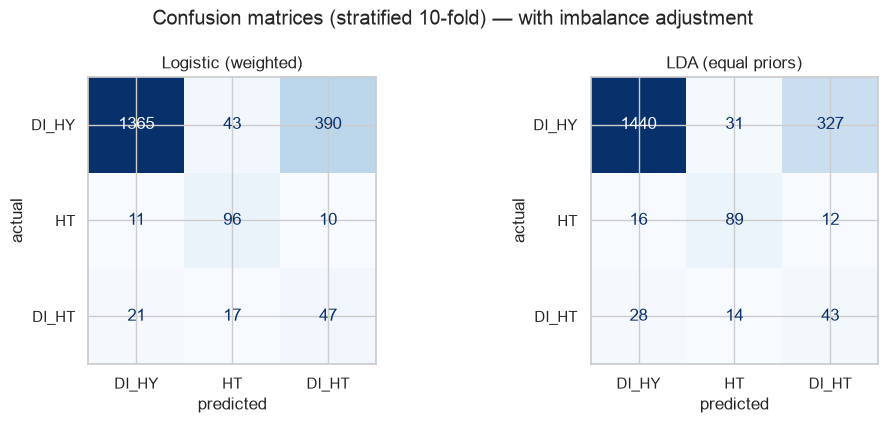

,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT,precision_DI_HT,n_predicted_DI_HT
Logistic,0.607,0.584,0.934,0.991,0.692,0.071,0.429,14.000
LDA,0.656,0.617,0.934,0.986,0.675,0.188,0.552,29.000
Logistic (weighted),0.578,0.711,0.754,0.759,0.821,0.553,0.105,447.000
LDA (equal priors),0.590,0.689,0.786,0.801,0.761,0.506,0.113,382.000


In [6]:
show_confusions(['Logistic (weighted)', 'LDA (equal priors)'], cv_preds,
                'Confusion matrices (stratified 10-fold) — with imbalance adjustment')
versions = pd.DataFrame({n: metrics(y, p) for n, p in cv_preds.items()}).T
for n, p in cv_preds.items():
    versions.loc[n, 'precision_DI_HT'] = precision_score(y, p, labels=['DI_HT'], average='macro', zero_division=0)
    versions.loc[n, 'n_predicted_DI_HT'] = (p == 'DI_HT').sum()
versions

**Conclusions:** the adjusted versions detect many more minority-class patients, but at a price.

| | Macro F1 | Bal. acc. | Accuracy | Recall `DI_HY` | Recall `HT` | Recall `DI_HT` | Precision `DI_HT` | No. predicted `DI_HT` |
|---|---|---|---|---|---|---|---|---|
| Logistic | 0.607 | 0.584 | 0.934 | 0.991 | 0.692 | 0.071 | 0.429 | 14 |
| LDA | **0.656** | 0.617 | **0.934** | 0.986 | 0.675 | 0.188 | **0.552** | 29 |
| Logistic (weighted) | 0.578 | **0.711** | 0.754 | 0.759 | **0.821** | **0.553** | 0.105 | 447 |
| LDA (equal priors) | 0.590 | 0.689 | 0.786 | 0.801 | 0.761 | 0.506 | 0.113 | 382 |

- **Gain:** the recall of `DI_HT` rises from 0.07 to **0.55** (Logistic) and from 0.19 to **0.51** (LDA). The recall
  of `HT` also increases. *Balanced accuracy* improves a lot (0.58 → 0.71 and 0.62 → 0.69).
- **Cost:** to find more `DI_HT`, the models start classifying many `DI_HY` patients as `DI_HT`. The weighted
  Logistic model predicts 447 `DI_HT` when only 85 exist. **`DI_HT` precision drops to ≈ 0.11** (only 1 in 9 `DI_HT`
  predictions is right) and *accuracy* falls to 0.75–0.79.
- **Macro F1 drops slightly**, because it combines recall and precision: the gain in minority-class recall is offset
  by the drop in `DI_HT` precision and `DI_HY` recall.

**Justification — why is there "no free lunch"?** The `DI_HT` and `DI_HY` classes overlap heavily (EDA). Changing
weights or priors **does not create new information**: it only moves the decision boundary. In the overlap region,
either the `DI_HT` are lost (unadjusted versions) or they are caught together with many `DI_HY` (adjusted versions).
It is the same trade-off obtained by lowering the decision threshold of a classifier.

**Which version is better?** It depends on which error is more costly:
- if the goal is **not to miss** `DI_HT`/`HT` patients (screening), the adjusted versions are preferable;
- if the goal is **to avoid false diagnoses**, the unadjusted versions are preferable.

Since the imbalance is the central feature of this problem, and the assignment asks for appropriate metrics, **we
always compare both methods in both versions** in the following sections.

### 2.4 Which version to use? Comparison with statistical significance

The differences between versions may be small. To know whether they are **real** or due to which patients fell into
each fold, we compute macro F1 and *balanced accuracy* on **each of the 10 folds**, using
the **same partitions** for all models, and apply a **paired *t*-test** between models.

In [7]:
fold_scores = {}
for n, m in MODELS.items():
    r = cross_validate(m, X, y, cv=CV10, scoring={'f1_macro': 'f1_macro', 'bal_acc': 'balanced_accuracy'})
    fold_scores[n] = pd.DataFrame({'f1_macro': r['test_f1_macro'], 'bal_acc': r['test_bal_acc']})

summary = pd.DataFrame({n: {'F1 macro (mean)': s.f1_macro.mean(), 'F1 macro (sd)': s.f1_macro.std(),
                            'Bal. acc. (mean)': s.bal_acc.mean(), 'Bal. acc. (sd)': s.bal_acc.std()}
                        for n, s in fold_scores.items()}).T
display(summary)

pairs = [('LDA', 'Logistic'), ('LDA (equal priors)', 'Logistic (weighted)'),
         ('Logistic (weighted)', 'Logistic'), ('LDA (equal priors)', 'LDA')]
tests = []
for a, b in pairs:
    for met in ('f1_macro', 'bal_acc'):
        d = fold_scores[a][met] - fold_scores[b][met]
        tests.append({'comparison': f'{a}  vs  {b}', 'metric': met, 'mean difference': d.mean(),
                      'folds where A > B': f'{(d > 0).sum()}/10', 'p-value (paired t)': stats.ttest_rel(
                          fold_scores[a][met], fold_scores[b][met]).pvalue})
pd.DataFrame(tests)

,F1 macro (mean),F1 macro (sd),Bal. acc. (mean),Bal. acc. (sd)
Logistic,0.604,0.048,0.585,0.038
LDA,0.651,0.048,0.616,0.040
Logistic (weighted),0.579,0.037,0.713,0.062
LDA (equal priors),0.592,0.044,0.690,0.047


,comparison,metric,mean difference,folds where A > B,p-value (paired t)
0,LDA vs Logistic,f1_macro,0.047,7/10,0.054
1,LDA vs Logistic,bal_acc,0.031,7/10,0.119
2,LDA (equal priors) vs Logistic (weighted),f1_macro,0.013,7/10,0.369
3,LDA (equal priors) vs Logistic (weighted),bal_acc,-0.023,3/10,0.297
4,Logistic (weighted) vs Logistic,f1_macro,-0.025,4/10,0.183
5,Logistic (weighted) vs Logistic,bal_acc,0.128,10/10,0.000
6,LDA (equal priors) vs LDA,f1_macro,-0.059,2/10,0.043
7,LDA (equal priors) vs LDA,bal_acc,0.074,8/10,0.017


**Conclusions:**

| Comparison | Macro F1 | Balanced accuracy |
|---|---|---|
| **LDA vs Logistic** (unadjusted) | LDA +0.047, better in 7/10 folds, **p = 0.054** | LDA +0.031, 7/10 folds, p = 0.119 |
| **LDA (equal priors) vs Logistic (weighted)** | LDA +0.013, 7/10 folds, p = 0.369 | Logistic +0.023, 7/10 folds, p = 0.297 |
| Logistic (weighted) vs Logistic | −0.025, p = 0.183 | **+0.128, 10/10 folds, p < 0.001** |
| LDA (equal priors) vs LDA | **−0.059, p = 0.043** | **+0.074, p = 0.017** |

- **Without adjustment, LDA beats Logistic Regression on macro F1** in 7 of the 10 folds (+0.047), but the
  difference is **borderline significant** (p = 0.054, just above 0.05).
- **With adjustment, the two methods are statistically tied**: LDA has a slightly higher macro F1 and Logistic
  Regression a slightly higher *balanced accuracy*, but neither difference is significant (p > 0.29).
- **Adjusting for imbalance** always improves *balanced accuracy* significantly (Logistic Regression improves in all 10
  folds), at the cost of a small drop in macro F1 (significant for LDA).

**Justification:** a paired test compares the two models **on the same folds**, removing the variability that comes
from which patients fell into each fold. This is why it can detect differences that means alone do not show. The
between-fold standard deviations (0.037–0.062) are of the same order as the differences between models, which is why
most of the LDA vs Logistic differences are not significant. Since the 10 folds share training data, they are not
fully independent, and the p-values should be read as indicative.

## 3. Resampling methods

The assignment asks for four ways of estimating performance on new patients. They all answer the same question
(*"how will the model perform on data it has never seen?"*), but in different ways, with different **cost, bias and
variance**.

| Method | Training in each repetition | Test | No. of models |
|---|---|---|---|
| *Holdout* | 70% (1400) | 30% (600), once | 1 |
| *k-fold* (k = 5 / 10) | (k−1)/k of the data (1600 / 1800) | each fold once | 5 / 10 |
| LOOCV | 1999 | 1 patient, 2000 times | 2000 |
| *Bootstrap* OOB | 2000 drawn with replacement (~63% distinct) | the ~37% left out | 200 |

**Precautions common to all methods:**
- standardisation (`StandardScaler`) is inside a *pipeline*, so it is fitted **only on the training data of each
  repetition**. Fitting it on all the data would leak information from the test set into training;
- whenever possible we use **stratification**, so that every class is represented in the test set;
- we evaluate **all four models** from section 2 with every method.

### 3.1 *Holdout* (validation set approach)

**How it works:** the data are split once into training (70%) and test (30%); the model learns on the
training set and is evaluated on the test set. We use a **stratified** split so that the 3 classes appear in the test
set in the same proportions as in the dataset: with only 85 `DI_HT`, a non-stratified split could leave the test set
with very few of them.

We show the full report (`classification_report`) for the four models.

In [8]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
print('Test:', y_te.value_counts().to_dict())
holdout = {}
for n, m in MODELS.items():
    pred = clone(m).fit(X_tr, y_tr).predict(X_te)
    holdout[n] = metrics(y_te, pred)
    if n in ('Logistic (weighted)', 'LDA (equal priors)'):
        print(f'\n=== {n} ===')
        print(classification_report(y_te, pred, labels=CLASSES, digits=3, zero_division=0))
pd.DataFrame(holdout).T

Test: {'DI_HY': 539, 'HT': 35, 'DI_HT': 26}

=== Logistic (weighted) ===
              precision    recall  f1-score   support

       DI_HY      0.969     0.800     0.876       539
          HT      0.508     0.857     0.638        35
       DI_HT      0.062     0.231     0.098        26

    accuracy                          0.778       600
   macro avg      0.513     0.629     0.538       600
weighted avg      0.902     0.778     0.828       600


=== LDA (equal priors) ===
              precision    recall  f1-score   support

       DI_HY      0.967     0.861     0.911       539
          HT      0.588     0.857     0.698        35
       DI_HT      0.116     0.308     0.168        26

    accuracy                          0.837       600
   macro avg      0.557     0.675     0.592       600
weighted avg      0.908     0.837     0.866       600



,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT
Logistic,0.581,0.606,0.937,0.989,0.829,0.000
LDA,0.609,0.602,0.932,0.985,0.743,0.077
Logistic (weighted),0.538,0.629,0.778,0.800,0.857,0.231
LDA (equal priors),0.592,0.675,0.837,0.861,0.857,0.308


**Conclusions:** the test set has 539 `DI_HY`, 35 `HT` and only **26 `DI_HT`**.

| | Macro F1 | Bal. acc. | Recall `HT` | Recall `DI_HT` |
|---|---|---|---|---|
| Logistic | 0.581 | 0.606 | 0.829 | **0.000** |
| LDA | 0.609 | 0.602 | 0.743 | 0.077 |
| Logistic (weighted) | 0.538 | 0.629 | 0.857 | 0.231 |
| LDA (equal priors) | **0.592** | **0.675** | 0.857 | **0.308** |

- The reports show the same pattern as in section 2: `DI_HY` and `HT` are well identified (F1 of 0.88–0.91 and
  0.64–0.70), and **`DI_HT` is the problematic class** (F1 0.10–0.17, precision 0.06–0.12).
- Unadjusted Logistic Regression **identifies none of the 26 `DI_HT`** in the test set.
- In this particular *holdout*, LDA with equal priors is the best on both main metrics.

**Justification — why distrust a single *holdout*?** The results differ from those of cross-validation (e.g. the
`DI_HT` recall of weighted Logistic Regression is 0.23 here versus 0.55 in 10-fold). With only 26 `DI_HT` in the
test set, **each `DI_HT` patient correctly classified or missed changes the recall by ~4 percentage points**. The
estimate depends heavily on which patients ended up in the test set, which we measure next.

### 3.2 How much does the *holdout* vary? Repeating the split 100 times

The result of a *holdout* depends on **which** patients ended up in the test set: the estimate has variance, and a
different split gives a different result. To measure this variance, we repeat the
stratified *holdout* with **100 different seeds** and look at how the metrics are distributed.

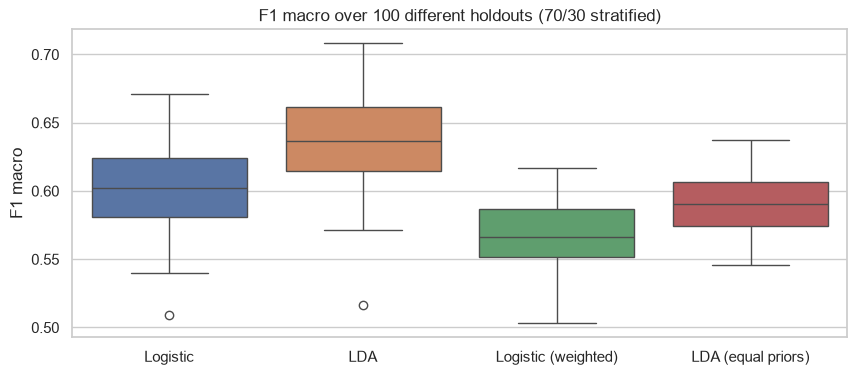

,mean,sd,min,max,recall DI_HT sd
Logistic,0.604,0.032,0.509,0.671,0.048
LDA,0.638,0.035,0.516,0.708,0.064
Logistic (weighted),0.567,0.024,0.503,0.617,0.104
LDA (equal priors),0.590,0.021,0.546,0.637,0.102


In [9]:
def repeated_holdout(model, n_rep=100, test_size=0.30):
    out = []
    for s in range(n_rep):
        a, b, c, d = train_test_split(X, y, test_size=test_size, stratify=y, random_state=s)
        out.append(metrics(d, clone(model).fit(a, c).predict(b)))
    return pd.DataFrame(out)

rep_holdout = {n: repeated_holdout(MODELS[n]) for n in MODELS}
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=pd.DataFrame({n: r.f1_macro for n, r in rep_holdout.items()}), ax=ax)
ax.set_ylabel('F1 macro'); ax.set_title('F1 macro over 100 different holdouts (70/30 stratified)')
plt.show()
pd.DataFrame({n: {'mean': r.f1_macro.mean(), 'sd': r.f1_macro.std(), 'min': r.f1_macro.min(),
                  'max': r.f1_macro.max(), 'recall DI_HT sd': r.recall_DI_HT.std()}
              for n, r in rep_holdout.items()}).T

**Conclusions:** repeating the *holdout* 100 times shows that **the same methodology gives very different results
depending on the split**:

| | Mean macro F1 | Standard deviation | Minimum | Maximum | sd of `DI_HT` recall |
|---|---|---|---|---|---|
| Logistic | 0.604 | 0.032 | 0.509 | 0.671 | 0.048 |
| LDA | 0.638 | 0.035 | 0.516 | 0.708 | 0.064 |
| Logistic (weighted) | 0.567 | 0.024 | 0.503 | 0.617 | **0.104** |
| LDA (equal priors) | 0.590 | **0.021** | 0.546 | 0.637 | **0.102** |

- The macro F1 of LDA ranges between **0.52 and 0.71** depending on the split: a difference of 0.19 purely by
  chance.
- The recall of `DI_HT` has a standard deviation of **0.10**: it can be 0.3 in one split and 0.6 in another.
- The single *holdout* in section 3.1 (0.538 for weighted Logistic Regression) is **below the mean** of the 100
  repetitions (0.567). Had we only made that split, we would have underestimated the model.

**Justification — where does this variance come from?**
1. **Small test set for the rare classes:** only ~26 `DI_HT` and ~35 `HT` in each test set, so a few patients change
   the per-class metrics a lot.
2. **Reduced training set:** the model learns from 70% of the data, i.e. only ~60 `DI_HT`. Different splits produce
   different models.
3. **A single measurement:** there is no average over several evaluations to "smooth out" chance.

Interestingly, the adjusted versions have a **more stable** macro F1 (sd 0.021–0.024) than the unadjusted ones
(0.032–0.035). Without adjustment, the `DI_HT` F1 depends on getting a handful of cases right, and swings between
close to 0 and reasonable values from split to split.

### 3.3 *k-fold* cross-validation (k = 5 and k = 10)

**How it works:** the data are divided into *k* parts (*folds*); each fold serves once as the test
set while the other *k−1* train the model. Every patient is tested **exactly once**. We use the **stratified** version:
with imbalanced classes, each fold keeps the class proportions.

There are **two kinds of variance** to distinguish:
1. **Between folds:** how much the *k* metrics vary within a single cross-validation;
2. **Of the estimate:** how much the final **mean** changes if we repeat the cross-validation with another random
   partition. We repeat it 20 times, with 20 seeds.

In [10]:
def repeated_kfold(model, k, n_rep=20):
    fold_level, means = [], []
    for s in range(n_rep):
        cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=s)
        r = cross_validate(model, X, y, cv=cv, scoring={'f1_macro': 'f1_macro', 'bal_acc': 'balanced_accuracy'})
        fold_level.append(r['test_f1_macro'])
        means.append({'f1_macro': r['test_f1_macro'].mean(), 'bal_acc': r['test_bal_acc'].mean()})
    return np.concatenate(fold_level), pd.DataFrame(means)

kfold = {}
for k in (5, 10):
    for n in MODELS:
        folds, means = repeated_kfold(MODELS[n], k)
        kfold[(k, n)] = {'folds': folds, 'means': means}

kfold_table = pd.DataFrame({f'{k}-fold | {n}': {
    'F1 macro (estimate)': v['means'].f1_macro.mean(),
    'sd between folds': v['folds'].std(),
    'sd of estimate (20 repeats)': v['means'].f1_macro.std(),
    'Bal. acc. (estimate)': v['means'].bal_acc.mean()} for (k, n), v in kfold.items()}).T
kfold_table

,F1 macro (estimate),sd between folds,sd of estimate (20 repeats),Bal. acc. (estimate)
5-fold | Logistic,0.608,0.039,0.010,0.586
5-fold | LDA,0.642,0.049,0.010,0.608
5-fold | Logistic (weighted),0.573,0.025,0.007,0.707
5-fold | LDA (equal priors),0.586,0.027,0.006,0.682
10-fold | Logistic,0.612,0.058,0.010,0.591
10-fold | LDA,0.647,0.068,0.009,0.613
10-fold | Logistic (weighted),0.575,0.038,0.004,0.709
10-fold | LDA (equal priors),0.586,0.040,0.006,0.683


**Conclusions:**

| | Macro F1 estimate | sd between folds | sd of estimate (20 rep.) | Bal. acc. |
|---|---|---|---|---|
| 5-fold · Logistic (weighted) | 0.573 | 0.025 | 0.007 | 0.707 |
| 5-fold · LDA (equal priors) | 0.586 | 0.027 | 0.006 | 0.682 |
| 10-fold · Logistic (weighted) | 0.575 | 0.038 | **0.004** | 0.709 |
| 10-fold · LDA (equal priors) | 0.586 | 0.040 | 0.006 | 0.683 |
| 10-fold · LDA (unadjusted) | **0.647** | 0.068 | 0.009 | 0.613 |

1. **The cross-validation estimate is much more stable than the *holdout* estimate.** Repeating with another
   partition, the 10-fold mean changes by only 0.004–0.010 (standard deviation), versus 0.021–0.035 for the
   *holdout*: a **3- to 6-fold reduction**. This is because the mean of *k* evaluations cancels much of the chance
   effect, and because **every patient is used as test data** once.
2. **Between-fold variability is higher with k = 10 than with k = 5** (e.g. 0.038 vs 0.025). With k = 10, each test
   fold has only ~200 patients and ~8–9 `DI_HT`, so each individual evaluation is "noisier".
3. **Even so, the final estimate is as stable or more stable with k = 10**, because it averages more evaluations.
4. **The estimate rises slightly from k = 5 to k = 10** (0.573 → 0.575 for weighted Logistic Regression). With
   k = 10 the model trains on 1800 patients instead of 1600 and learns the rare classes slightly better: k = 5 is
   slightly more **pessimistic**.
5. **The ranking of the models is preserved:** LDA > Logistic on macro F1, weighted Logistic > LDA (equal priors) on
   *balanced accuracy*.

### 3.4 *Leave-One-Out* (LOOCV)

**How it works:** it is the extreme case of *k-fold*, with *k = N* = 2000. The model is trained 2000
times, always with 1999 patients, and tested on the patient left out.

Two important particularities:
- each fold has **a single patient**, so a "per-fold F1" does not exist (with a single prediction you can only be
  right or wrong). The metrics are computed by pooling the 2000 predictions;
- LOOCV is **deterministic**: there is only one way to leave each patient out, so repeating it always gives the same
  result. It also cannot be stratified.

In [11]:
loo_preds, loo_time = {}, {}
for n, m in MODELS.items():
    t0 = time.time()
    loo_preds[n] = cross_val_predict(m, X, y, cv=LeaveOneOut(), n_jobs=-1)
    loo_time[n] = time.time() - t0
loo_table = pd.DataFrame({n: {**metrics(y, p), 'time (s)': loo_time[n], 'n models trained': len(y)}
                          for n, p in loo_preds.items()}).T
loo_table

,f1_macro,bal_acc,accuracy,recall_DI_HY,recall_HT,recall_DI_HT,time (s),n models trained
Logistic,0.628,0.596,0.935,0.991,0.692,0.106,5.269,2000.000
LDA,0.662,0.621,0.935,0.987,0.675,0.200,2.590,2000.000
Logistic (weighted),0.575,0.706,0.746,0.750,0.803,0.565,4.359,2000.000
LDA (equal priors),0.585,0.681,0.780,0.795,0.752,0.494,2.451,2000.000


**Conclusions:**

| | Macro F1 | Bal. acc. | Recall `DI_HT` | Time |
|---|---|---|---|---|
| Logistic | 0.628 | 0.596 | 0.106 | ~5.5 s |
| LDA | **0.662** | 0.621 | 0.200 | ~2.5 s |
| Logistic (weighted) | 0.575 | **0.706** | **0.565** | ~4.5 s |
| LDA (equal priors) | 0.585 | 0.681 | 0.494 | ~2.5 s |

- For the unadjusted versions, LOOCV gives the **highest** estimates of all methods (e.g. LDA 0.662 vs 0.647 in
  10-fold and 0.638 for the *holdout* ×100). Each model trains on 1999 patients, almost the full dataset, so it is the
  **least pessimistic (least biased)** method. For the adjusted versions, LOOCV is practically equal to 10-fold
  (0.575 and 0.585 versus 0.575 and 0.586).
- The conclusions are the same: without adjustment LDA is better; with adjustment LDA has the better macro F1 and
  Logistic Regression the better *balanced accuracy*.
- The cost was low (a few seconds, with parallel processing; times vary slightly between runs), because these models
  are fast to train. With heavier models, 2000 fits per model would be prohibitive.

**Variance of LOOCV:**
- **Repeating LOOCV always gives the same result** (partition variance = 0): there is only one way to leave each
  patient out.
- However, **this does not mean the estimate is precise**. The 2000 models are almost identical (they differ by one
  patient), so their errors are highly correlated. According to theory (ISLP, 5.1.4), the LOOCV estimate has **high
  variance with respect to the true error**: had we collected another 2000 patients, the LOOCV result could change
  considerably.
- It is also **not possible to stratify** and there is no "per-fold metric" (each fold has a single patient), so
  there is no way to measure the spread from the results themselves.

### 3.5 *Bootstrap* with *out-of-bag* (OOB) evaluation

**How it works:** at each iteration we draw a sample **with replacement**
of the same size as the dataset (2000). Some patients appear repeated and others are left out; the probability of a
patient being left out is $(1 - 1/N)^N pprox e^{-1} pprox 36.8\%$. The model trains on the *bootstrap* sample
and is evaluated on the left-out (*out-of-bag*) patients, which it never saw.

We repeat this **200 times** and obtain the distribution of the metrics, the mean, the
standard deviation and a 95% confidence interval (2.5th and 97.5th percentiles).

In [12]:
def bootstrap_oob(model, B=200, seed=SEED):
    rng = np.random.default_rng(seed)
    idx_all = np.arange(len(y))
    out = []
    for _ in range(B):
        inb = rng.choice(idx_all, size=len(y), replace=True)
        oob = np.setdiff1d(idx_all, inb)
        m = clone(model).fit(X.iloc[inb], y.iloc[inb])
        out.append({**metrics(y.iloc[oob], m.predict(X.iloc[oob])), 'oob_frac': len(oob) / len(y),
                    'n_DI_HT_oob': (y.iloc[oob] == 'DI_HT').sum()})
    return pd.DataFrame(out)

boot = {n: bootstrap_oob(MODELS[n]) for n in MODELS}
boot_table = pd.DataFrame({n: {'F1 macro (mean)': b.f1_macro.mean(), 'sd': b.f1_macro.std(),
                               'IC95% inf': b.f1_macro.quantile(.025), 'IC95% sup': b.f1_macro.quantile(.975),
                               'Bal. acc. (mean)': b.bal_acc.mean(), 'mean OOB fraction': b.oob_frac.mean(),
                               'n DI_HT in OOB (mean)': b.n_DI_HT_oob.mean()} for n, b in boot.items()}).T
boot_table

,F1 macro (mean),sd,IC95% inf,IC95% sup,Bal. acc. (mean),mean OOB fraction,n DI_HT in OOB (mean)
Logistic,0.615,0.030,0.563,0.689,0.592,0.367,30.565
LDA,0.640,0.029,0.580,0.701,0.605,0.367,30.565
Logistic (weighted),0.561,0.022,0.521,0.606,0.695,0.367,30.565
LDA (equal priors),0.592,0.021,0.546,0.629,0.687,0.367,30.565


**Conclusions:**

| | Mean macro F1 | sd | 95% CI | Bal. acc. |
|---|---|---|---|---|
| Logistic | 0.615 | 0.030 | [0.563, 0.689] | 0.592 |
| LDA | **0.640** | 0.029 | [0.580, 0.701] | 0.605 |
| Logistic (weighted) | 0.561 | 0.022 | [0.521, 0.606] | **0.695** |
| LDA (equal priors) | 0.592 | **0.021** | [0.546, 0.629] | 0.687 |

- The mean fraction of *out-of-bag* patients is **0.367**, exactly the theoretical value $e^{-1} \approx 0.368$.
  Each OOB set contains on average ~31 `DI_HT`.
- The *bootstrap* returns a **full distribution** and a **confidence interval** for the performance. The LDA and
  Logistic intervals overlap considerably, confirming that the differences between the two methods are modest.
- For weighted Logistic Regression, the estimate is **lower** than that of 10-fold and LOOCV: 0.561 versus 0.575.

**Justification — why is the *bootstrap* pessimistic?** Each *bootstrap* sample has 2000 patients, but only ~63% are
**distinct** (the rest are repetitions). In practice the model learns from ~1264 different patients, fewer than in
5-fold (1600). This affects Logistic Regression more, since it needs varied examples of the rare classes to estimate
its coefficients. LDA, which only needs means and a common covariance, is less affected (0.592 vs 0.586 in 10-fold).

## 4. How does the resampling method affect the variance?

This is the central question of the assignment: *"indicate how the variance is affected by the resampling methods
used"*. Here we bring together the results of sections 3.1–3.5.

### 4.1 Side-by-side comparison

For each method and model we show:
- the macro F1 **estimate**;
- the **variability of the individual evaluations** (between splits, folds or iterations);
- the **variability of the final estimate** (how much the estimate changes if the procedure is repeated);
- the **cost** (number of models trained).

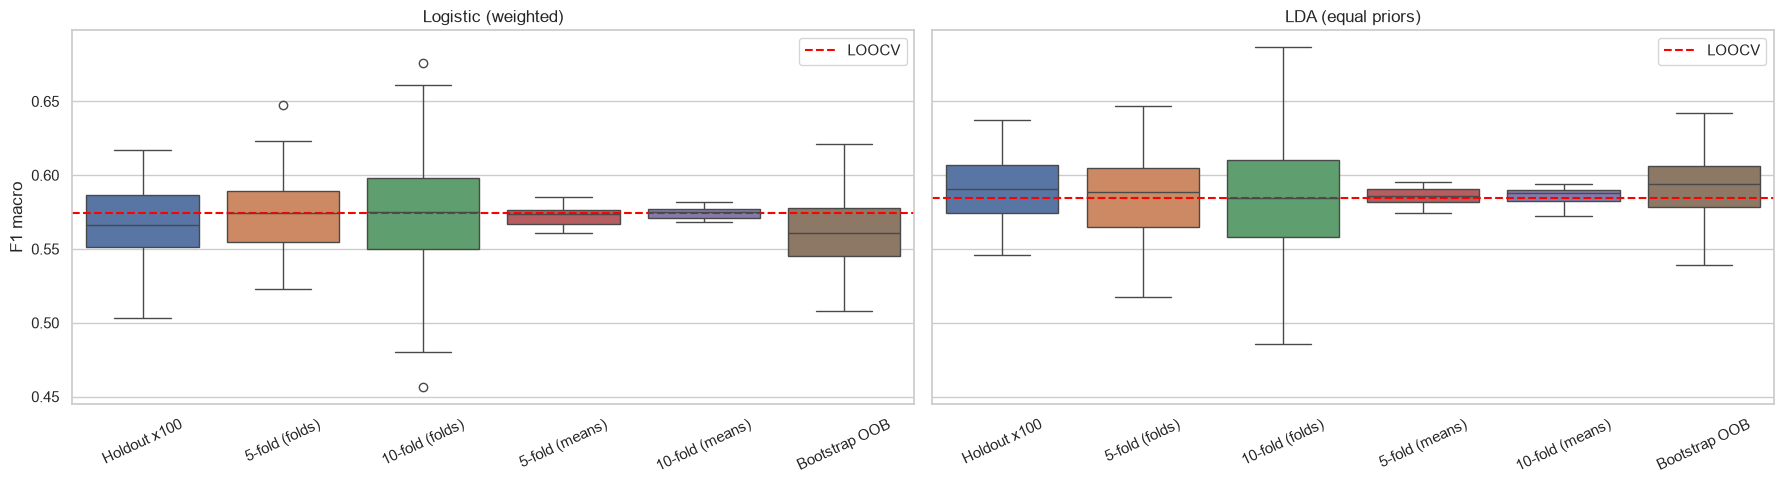

F1 macro  sd of evaluations  \
model               method                                               
Logistic (weighted) Holdout (1 split)         0.538                NaN   
                    5-fold stratified         0.573              0.025   
                    10-fold stratified        0.575              0.038   
                    LOOCV                     0.575                NaN   
                    Bootstrap OOB (B=200)     0.561              0.022   
LDA (equal priors)  Holdout (1 split)         0.592                NaN   
                    5-fold stratified         0.586              0.027   
                    10-fold stratified        0.586              0.040   
                    LOOCV                     0.585                NaN   
                    Bootstrap OOB (B=200)     0.592              0.021   

                                           sd of estimate  n models  
model               method                                           
Logistic (weighted) Holdout (1 split)               0.024         1  
                    5-fold stratified               0.007         5  
                    10-fold stratified              0.004        10  
                    LOOCV                           0.000      2000  
                    Bootstrap OOB (B=200)           0.002       200  
LDA (equal priors)  Holdout (1 split)               0.021         1  
                    5-fold stratified               0.006         5  
                    10-fold stratified              0.006        10  
                    LOOCV                           0.000      2000  
                    Bootstrap OOB (B=200)           0.001       200

In [13]:
rows = []
for n in MODELS:
    rows.append({'model': n, 'method': 'Holdout (1 split)', 'F1 macro': holdout[n]['f1_macro'],
                 'sd of evaluations': np.nan, 'sd of estimate': rep_holdout[n].f1_macro.std(), 'n models': 1})
    for k in (5, 10):
        v = kfold[(k, n)]
        rows.append({'model': n, 'method': f'{k}-fold stratified', 'F1 macro': v['means'].f1_macro.mean(),
                     'sd of evaluations': v['folds'].std(), 'sd of estimate': v['means'].f1_macro.std(), 'n models': k})
    rows.append({'model': n, 'method': 'LOOCV', 'F1 macro': loo_table.loc[n, 'f1_macro'],
                 'sd of evaluations': np.nan, 'sd of estimate': 0.0, 'n models': len(y)})
    rows.append({'model': n, 'method': 'Bootstrap OOB (B=200)', 'F1 macro': boot[n].f1_macro.mean(),
                 'sd of evaluations': boot[n].f1_macro.std(),
                 'sd of estimate': boot[n].f1_macro.std() / np.sqrt(len(boot[n])), 'n models': 200})
variance = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)
for ax, n in zip(axes, ['Logistic (weighted)', 'LDA (equal priors)']):
    dist = pd.DataFrame({'Holdout x100': rep_holdout[n].f1_macro,
                         '5-fold (folds)': pd.Series(kfold[(5, n)]['folds']),
                         '10-fold (folds)': pd.Series(kfold[(10, n)]['folds']),
                         '5-fold (means)': kfold[(5, n)]['means'].f1_macro,
                         '10-fold (means)': kfold[(10, n)]['means'].f1_macro,
                         'Bootstrap OOB': boot[n].f1_macro})
    sns.boxplot(data=dist, ax=ax); ax.axhline(loo_table.loc[n, 'f1_macro'], color='red', ls='--', label='LOOCV')
    ax.set_title(n); ax.tick_params(axis='x', rotation=25); ax.legend()
axes[0].set_ylabel('F1 macro')
plt.tight_layout(); plt.show()
variance[variance.model.isin(['Logistic (weighted)', 'LDA (equal priors)'])].set_index(['model', 'method'])

**Conclusions (adjusted versions; the unadjusted versions follow the same pattern):**

| Method | F1 estimate (Log. weighted / LDA priors) | sd of evaluations | **sd of estimate** | No. of models |
|---|---|---|---|---|
| *Holdout* (1 split) | 0.538 / 0.592 | — | **0.024 / 0.021** | 1 |
| Stratified 5-fold | 0.573 / 0.586 | 0.025 / 0.027 | 0.007 / 0.006 | 5 |
| Stratified 10-fold | 0.575 / 0.586 | 0.038 / 0.040 | 0.004 / 0.006 | 10 |
| LOOCV | 0.575 / 0.585 | — | 0 (deterministic) | 2000 |
| *Bootstrap* OOB (B = 200) | 0.561 / 0.592 | 0.022 / 0.021 | 0.002 / 0.001 | 200 |

*The bootstrap "sd of estimate" is the standard error of the mean over the 200 iterations ($sd/\sqrt{200}$).*

**How does the resampling method affect the variance?**

1. ***Holdout*: the estimate with the highest variance.** It is a single measurement on a test set of 600 patients
   with ~26 `DI_HT`. The split alone can change macro F1 by ±0.04–0.05 (two standard deviations). As we saw, the
   single *holdout* fell below the mean of the repetitions.
2. ***k-fold*: much lower variance**, because each patient is tested once and the result is the mean of *k*
   evaluations. The estimate is **3 to 6 times more stable** than the *holdout*. Each individual fold varies more with
   larger *k* (smaller test folds), but the mean becomes more stable.
3. **LOOCV: no partition variance** (it is deterministic), but the 2000 trained models are almost identical and their
   errors are correlated. The estimate has low bias but **high variance with respect to the true error**, which
   cannot be measured from its own results.
4. ***Bootstrap*: the variance of each iteration is similar to that of a *holdout*** (sd 0.021–0.030), but averaging
   200 iterations makes the final estimate very stable. It is the only method that directly provides a **confidence
   interval**. The price is being **pessimistic**, because each model trains on only ~63% distinct patients.

**The plot** shows this visually: the boxes for individual evaluations (*holdout* ×100, folds, *bootstrap*) are wide,
while those for the 5-fold and 10-fold **means** are very narrow.

**Bias:** the less data the model uses for training, the more pessimistic the estimate. The ranking of the weighted
Logistic estimates follows this logic: *bootstrap* (~63% distinct patients) 0.561 < 5-fold (80%) 0.573 < 10-fold
(90%) 0.575 ≈ LOOCV (99.95%) 0.575. The *holdout* (70%) ended up even lower (0.538) due to an unlucky split. From
~90% of the training data onwards, the estimate practically stabilises.

### 4.2 The effect of *k* in cross-validation

Choosing *k* involves a trade-off:
- **small *k*** → each model trains on less data → **pessimistic** (more biased) estimate, but more stable and
  cheaper;
- **large *k*** (in the limit, LOOCV) → training on almost all the data → **low-bias** estimate, but the models are
  very similar to each other and the cost grows.

For *k* ∈ {2, 3, 5, 10, 20}, we measure the mean estimate, the variability **between folds** and the variability **of
the estimate** (10 repetitions with different seeds), for the weighted version of each model.

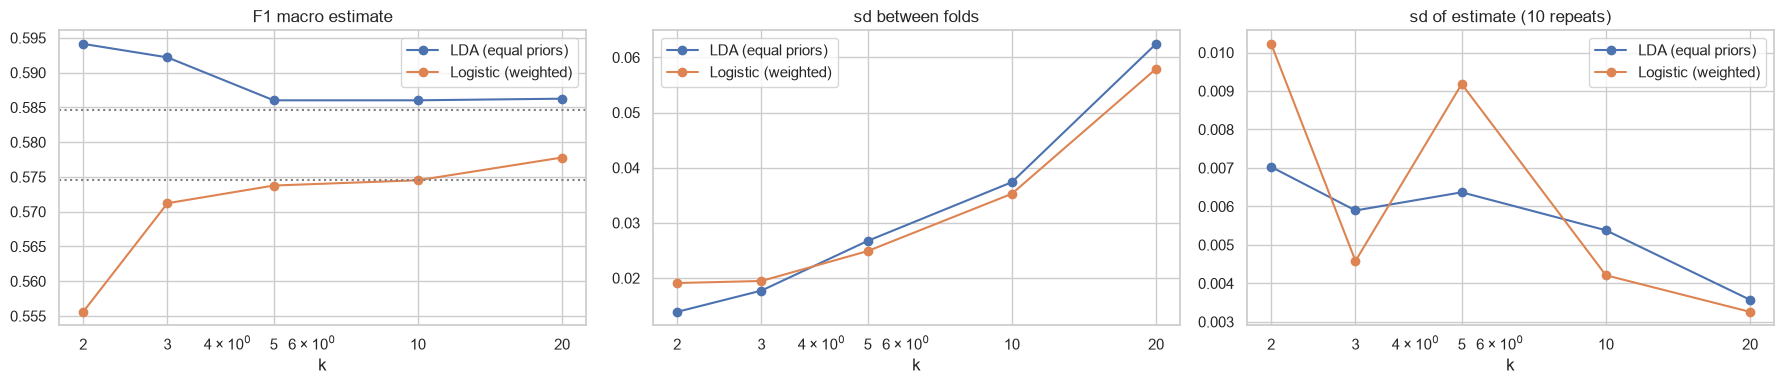

training size  DI_HT per test fold  F1 macro  \
model               k                                                  
Logistic (weighted) 2            1000               42.500     0.556   
                    3            1333               28.300     0.571   
                    5            1600               17.000     0.574   
                    10           1800                8.500     0.575   
                    20           1900                4.200     0.578   
LDA (equal priors)  2            1000               42.500     0.594   
                    3            1333               28.300     0.592   
                    5            1600               17.000     0.586   
                    10           1800                8.500     0.586   
                    20           1900                4.200     0.586   

                        sd between folds  sd of estimate  
model               k                                     
Logistic (weighted) 2              0.019           0.010  
                    3              0.019           0.005  
                    5              0.025           0.009  
                    10             0.035           0.004  
                    20             0.058           0.003  
LDA (equal priors)  2              0.014           0.007  
                    3              0.018           0.006  
                    5              0.027           0.006  
                    10             0.037           0.005  
                    20             0.062           0.004

In [14]:
k_rows = []
for n in ['Logistic (weighted)', 'LDA (equal priors)']:
    for k in (2, 3, 5, 10, 20):
        folds, means = repeated_kfold(MODELS[n], k, n_rep=10)
        k_rows.append({'model': n, 'k': k, 'training size': int(len(y) * (k - 1) / k),
                       'DI_HT per test fold': round(85 / k, 1), 'F1 macro': means.f1_macro.mean(),
                       'sd between folds': folds.std(), 'sd of estimate': means.f1_macro.std()})
k_effect = pd.DataFrame(k_rows)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for n, g in k_effect.groupby('model'):
    axes[0].plot(g.k, g['F1 macro'], marker='o', label=n)
    axes[1].plot(g.k, g['sd between folds'], marker='o', label=n)
    axes[2].plot(g.k, g['sd of estimate'], marker='o', label=n)
for ax, t in zip(axes, ['F1 macro estimate', 'sd between folds', 'sd of estimate (10 repeats)']):
    ax.set_xlabel('k'); ax.set_title(t); ax.set_xscale('log'); ax.set_xticks([2, 3, 5, 10, 20]); ax.set_xticklabels([2, 3, 5, 10, 20]); ax.legend()
for n in ['Logistic (weighted)', 'LDA (equal priors)']:
    axes[0].axhline(loo_table.loc[n, 'f1_macro'], ls=':', color='grey')
plt.tight_layout(); plt.show()
k_effect.set_index(['model', 'k'])

**Conclusions:**

| k | Training | `DI_HT` per fold | F1 Log. (weighted) | F1 LDA (priors) | sd between folds | sd of estimate |
|---|---|---|---|---|---|---|
| 2 | 1000 | 42.5 | 0.556 | 0.594 | 0.019 / 0.014 | **0.010 / 0.007** |
| 5 | 1600 | 17.0 | 0.574 | 0.586 | 0.025 / 0.027 | 0.009 / 0.006 |
| 10 | 1800 | 8.5 | 0.575 | 0.586 | 0.035 / 0.037 | 0.004 / 0.005 |
| 20 | 1900 | 4.2 | 0.578 | 0.586 | **0.058 / 0.062** | **0.003 / 0.004** |

1. **Bias:** the weighted Logistic estimate **increases with *k*** (0.556 → 0.578): with k = 2 the model trains on
   only half of the data and performance is underestimated. LDA is practically insensitive to *k* (0.586–0.594): it
   estimates few parameters (means and a common covariance), so it learns almost the same from 1000 or 1900 patients.
2. **Variance between folds:** **increases** with *k* (0.014–0.019 → 0.058–0.062). With k = 20, each test fold has
   only ~4 `DI_HT`, and a single patient correctly classified or missed changes that fold's F1 a lot.
3. **Variance of the estimate:** **tends to decrease** with *k* (0.010 → 0.003 for Logistic Regression), with some
   fluctuation at intermediate values. The mean of many folds is more stable than the mean of a few, and models
   trained on more data are more similar to each other.

**Justification — why k = 5 or k = 10?** Small *k* is pessimistic; *k* = N (LOOCV) has low bias but is expensive and
has high variance with respect to the true error. For this dataset, **k = 10 is a good balance**: the estimate
practically matches LOOCV, is stable across repetitions (sd ≈ 0.005) and costs 10 fits instead of 2000. With such
small classes, **it is not advisable to use *k* much larger than 10**, because the test folds would contain very few
patients from the rare classes.

## 5. Which method is most appropriate?

We gather the evidence from all resampling methods. If the ranking between Logistic Regression and LDA is the same
across all resampling methods, the conclusion is robust.

We also show the Logistic Regression **coefficients**, to confirm that the model uses the features the EDA identified
as informative.

In [15]:
decision = pd.DataFrame({
    'Holdout':           {n: holdout[n]['bal_acc'] for n in MODELS},
    'Holdout x100 (mean)': {n: rep_holdout[n].bal_acc.mean() for n in MODELS},
    '5-fold':            {n: kfold[(5, n)]['means'].bal_acc.mean() for n in MODELS},
    '10-fold':           {n: kfold[(10, n)]['means'].bal_acc.mean() for n in MODELS},
    'LOOCV':             {n: loo_table.loc[n, 'bal_acc'] for n in MODELS},
    'Bootstrap OOB':     {n: boot[n].bal_acc.mean() for n in MODELS},
})
decision_f1 = pd.DataFrame({
    'Holdout':           {n: holdout[n]['f1_macro'] for n in MODELS},
    'Holdout x100 (mean)': {n: rep_holdout[n].f1_macro.mean() for n in MODELS},
    '5-fold':            {n: kfold[(5, n)]['means'].f1_macro.mean() for n in MODELS},
    '10-fold':           {n: kfold[(10, n)]['means'].f1_macro.mean() for n in MODELS},
    'LOOCV':             {n: loo_table.loc[n, 'f1_macro'] for n in MODELS},
    'Bootstrap OOB':     {n: boot[n].f1_macro.mean() for n in MODELS},
})
print('=== Balanced accuracy by resampling method ===');  display(decision)
print('=== F1 macro by resampling method ===');           display(decision_f1)

lr = clone(MODELS['Logistic (weighted)']).fit(X, y)
coefs = pd.DataFrame(lr[-1].coef_.T, index=FEATURES, columns=lr[-1].classes_)
coefs['|coef| max'] = coefs.abs().max(axis=1)
coefs.sort_values('|coef| max', ascending=False).head(10)

=== Balanced accuracy by resampling method ===


,Holdout,Holdout x100 (mean),5-fold,10-fold,LOOCV,Bootstrap OOB
Logistic,0.606,0.586,0.586,0.591,0.596,0.592
LDA,0.602,0.603,0.608,0.613,0.621,0.605
Logistic (weighted),0.629,0.699,0.707,0.709,0.706,0.695
LDA (equal priors),0.675,0.688,0.682,0.683,0.681,0.687


=== F1 macro by resampling method ===


,Holdout,Holdout x100 (mean),5-fold,10-fold,LOOCV,Bootstrap OOB
Logistic,0.581,0.604,0.608,0.612,0.628,0.615
LDA,0.609,0.638,0.642,0.647,0.662,0.640
Logistic (weighted),0.538,0.567,0.573,0.575,0.575,0.561
LDA (equal priors),0.592,0.590,0.586,0.586,0.585,0.592


,DI_HT,DI_HY,HT,|coef| max
HbA1c_level,0.784,0.826,-1.610,1.610
triglycerides,0.523,-0.697,0.174,0.697
bmi_level,0.454,-0.353,-0.102,0.454
high_ldl_cholesterol,0.418,-0.136,-0.282,0.418
ldl,-0.340,0.164,0.176,0.340
employment_status_Retired,0.106,0.229,-0.335,0.335
physical_activity,0.305,-0.066,-0.239,0.305
employment_status_Unemployed,-0.186,0.303,-0.117,0.303
age,0.281,-0.197,-0.084,0.281
education_level,-0.248,-0.000,0.248,0.248


**Conclusions:**

**Macro F1 (main metric):**

| | Holdout | Holdout ×100 | 5-fold | 10-fold | LOOCV | Bootstrap |
|---|---|---|---|---|---|---|
| Logistic | 0.581 | 0.604 | 0.608 | 0.612 | 0.628 | 0.615 |
| **LDA** | **0.609** | **0.638** | **0.642** | **0.647** | **0.662** | **0.640** |
| Logistic (weighted) | 0.538 | 0.567 | 0.573 | 0.575 | 0.575 | 0.561 |
| LDA (equal priors) | 0.592 | 0.590 | 0.586 | 0.586 | 0.585 | 0.592 |

**Balanced accuracy:**

| | Holdout | Holdout ×100 | 5-fold | 10-fold | LOOCV | Bootstrap |
|---|---|---|---|---|---|---|
| Logistic | 0.606 | 0.586 | 0.586 | 0.591 | 0.596 | 0.592 |
| LDA | 0.602 | 0.603 | 0.608 | 0.613 | 0.621 | 0.605 |
| **Logistic (weighted)** | 0.629 | **0.699** | **0.707** | **0.709** | **0.706** | **0.695** |
| LDA (equal priors) | **0.675** | 0.688 | 0.682 | 0.683 | 0.681 | 0.687 |

- **Without adjustment, LDA beats Logistic Regression with every resampling method** on macro F1 (6/6), and on
  *balanced accuracy* in 5/6 (the exception is the single *holdout*, by 0.004).
- **With adjustment**, LDA has the better macro F1 with every method (6/6), and Logistic Regression has the better
  *balanced accuracy* with every method except the single *holdout* (5/6). The differences are small and not
  significant (2.4).
- The **ranking of the models is the same with every resampling method**: what changes is the level of the estimate
  (the bias), not the conclusion. This makes the decision robust.

**Logistic Regression coefficients:** the most important features are **`HbA1c_level`** (coefficient −1.61 for `HT`:
the lower it is, the more likely `HT`) and **`triglycerides`** (+0.52 for `DI_HT`, −0.70 for `DI_HY`), followed by
`bmi_level` and `high_ldl_cholesterol`. These are mainly the features the EDA identified as informative. The model is
learning patterns that make clinical sense, not noise. The coefficients of features such as `employment_status` and
`education_level` are smaller and will be assessed with Lasso in the feature selection part.

## 6. Conclusions and choice of method

### 6.1 Which method is most appropriate? → **LDA**

| Criterion | Logistic | LDA | Advantage |
|---|---|---|---|
| Macro F1 without adjustment (all methods) | 0.58–0.63 | **0.61–0.66** | LDA, borderline significant (p = 0.054) |
| Macro F1 with adjustment (all methods) | 0.54–0.58 | **0.59** | LDA, 6/6 methods (not significant) |
| Balanced accuracy with adjustment | **0.63–0.71** | 0.68–0.69 | Logistic, 5/6 methods (not significant) |
| `DI_HT` detection without adjustment (recall) | 0.07–0.11 | **0.19–0.20** | LDA (about 2× more cases) |
| False `DI_HT` with adjustment (10-fold) | 447 predicted | **382 predicted** | LDA (fewer false alarms) |
| Stability (sd over 100 *holdouts*, adjusted) | 0.024 | **0.021** | LDA |
| Sensitivity to less training data (k = 2 → 20; *bootstrap*) | sensitive (0.556 → 0.578) | **stable** (≈ 0.59) | LDA |
| Assumptions | **none** | normality and equal covariances (violated) | Logistic |
| Computational cost (LOOCV) | ~4.5–5.5 s | **~2.5 s** | LDA |

**Justification:**
1. **Better performance on the main metric**, with every resampling method and in both versions (with and without
   adjustment). In the unadjusted version the difference is borderline significant (p = 0.054).
2. **Better with small classes.** With only 85 `DI_HT`, LDA benefits from estimating shared parameters (a common
   covariance for all classes), which gives it more stable estimates. Logistic Regression has to estimate 30
   coefficients per class from few examples. LDA is especially useful when there are few examples and the classes are
   well separated, as `HT` is by `HbA1c_level`.
3. **More stable:** lower variance across splits and almost insensitive to the amount of training data.
4. **Despite the violated assumptions**, LDA's linear boundaries work well, confirming its robustness in practice. The
   theoretical advantage of Logistic Regression (having no assumptions) did not translate into better performance.

**Honest caveat:** if the criterion were **only** *balanced accuracy* with imbalance adjustment, weighted Logistic
Regression would be slightly better (0.709 vs 0.683 in 10-fold). Since this difference is not significant
(p = 0.297), and LDA wins on almost every other criterion, the recommendation stands.

**Which version of LDA?** The choice depends on the cost of errors:
- **LDA with equal priors**, if the goal is to **detect** `HT`/`DI_HT` patients (screening). `DI_HT` recall rises
  from ~0.19 to ~0.51, but with many false alarms (precision ≈ 0.11);
- **unadjusted LDA**, if the goal is to maximise macro F1 and **avoid false diagnoses**, accepting that most `DI_HT`
  go unnoticed.

In a clinical context, missing a diagnosis is usually more serious than a false alarm that leads to further tests.
We therefore **recommend LDA with equal priors**.

### 6.2 How the variance is affected by the resampling methods
| Method | Bias | Variance of the estimate | Cost | When to use |
|---|---|---|---|---|
| *Holdout* | pessimistic (trains on 70%) | **the highest** (sd 0.02–0.035; F1 between 0.50 and 0.71) | 1 fit | final test set, very large datasets |
| 5-fold | slightly pessimistic | low (sd ≈ 0.006–0.010) | 5 fits | good compromise, small data or expensive models |
| **10-fold** | small | **low** (sd ≈ 0.004–0.010) | 10 fits | **recommended for this dataset** |
| LOOCV | the lowest | 0 across repetitions, but high with respect to the true error (correlated models) | 2000 fits | very small datasets, cheap models |
| *Bootstrap* OOB | pessimistic (~63% distinct patients) | low on average; provides confidence intervals | 200 fits | when uncertainty needs to be quantified |

**Key ideas:**
- **Averaging several evaluations reduces variance.** That is why *k-fold* and *bootstrap* are much more stable than
  a single *holdout*.
- **Individual evaluations with little test data are noisy**, especially for the rare classes: with k = 20, each fold
  has ~4 `DI_HT`.
- **Training on less data makes the estimate pessimistic** (*bootstrap*, small *k*, *holdout*). Training on almost
  all of it (LOOCV) reduces bias, but increases cost and the correlation between models.
- **Stratification is essential** with this imbalance: it ensures each test set has enough `HT` and `DI_HT`.
- **The conclusion (LDA vs Logistic) was the same with every method.** The resampling method changes how confident we
  can be in the estimate, not the ranking of the models.

### 6.3 Limitations and next steps
- **`DI_HT` remains hard:** the F1 of this class never exceeds ~0.2. The overlap with `DI_HY` limits any linear
  classifier, and the features do not contain the information needed to separate these classes better.
- **LDA probabilities:** with the assumptions violated, the probabilities estimated by LDA may not be well calibrated.
  The classification remains valid, but the probabilities should be interpreted with caution.
- **The decimal-precision artefact** identified in the EDA is not exploited by these linear models, but its origin
  should be confirmed with the lecturer.
- **Next steps (feature selection):** apply Ridge (L2) and Lasso (L1) regularisation to Logistic Regression, compare
  all features against a reduced set, use **stratified 10-fold** as the evaluation method (justified in section 4),
  and check whether Lasso keeps mainly `HbA1c_level`, `triglycerides`, `age` and `bmi`.

### References
- James, Witten, Hastie & Tibshirani — *An Introduction to Statistical Learning with Python* (ISLP), ch. 4
  (classification) and ch. 5 (resampling methods).
- scikit-learn documentation (`LogisticRegression`, `LinearDiscriminantAnalysis`, `StratifiedKFold`, `LeaveOneOut`).